## Test out correlation function calculation on clustering BGS catalog ##
Rather than custom stellar mass-limited catalog

In [1]:
#use cosmodesi kernel

from abacusnbody.data.read_abacus import read_asdf
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
from pycorr.correlation_function import TwoPointCorrelationFunction, JackknifeTwoPointCounter
from pycorr.twopoint_jackknife import JackknifeTwoPointEstimator
import matplotlib
from astropy.table import Table, vstack, hstack, join
import fitsio
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
from tools import *

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['figure.titlesize'] = 16

In [2]:
#get table of bgs galaxies
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
#bgsN = Table(fitsio.read(bgsdir+"BGS_BRIGHT_NGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT","BITWEIGHTS"]))
bgsS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_clustering.dat.fits",columns = ['RA','DEC',"Z","TARGETID","WEIGHT","BITWEIGHTS"]))
bgs_clustering = bgsS

In [3]:
bgs_clustering = bgs_clustering[(bgs_clustering['Z'] < 0.25)&(bgs_clustering['Z'] > 0.2)]

In [4]:
#get table of bgs randoms
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
rantabs = []
#for i in range(18):
for i in range(1):
    bgsranS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    rantabs.append(bgsranS)
bgsrantab = vstack(rantabs)

In [5]:
bgsrantab = bgsrantab[(bgsrantab['Z'] < 0.25)&(bgsrantab['Z'] > 0.2)]

In [6]:
bgs_clustering['dist'] = cosmo.comoving_distance(bgs_clustering['Z'])*cosmo.h/u.Mpc
bgsrantab['dist'] = cosmo.comoving_distance(bgsrantab['Z'])*cosmo.h/u.Mpc

In [7]:
tabbgs = bgs_clustering

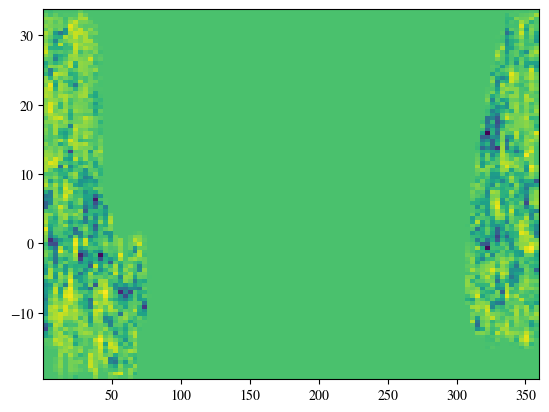

In [8]:
hist1,binsx,binsy = np.histogram2d(tabbgs['RA'],tabbgs['DEC'],bins = 100,density=True)
hist2,binsx,binsy = np.histogram2d(bgsrantab['RA'],bgsrantab['DEC'],bins = [binsx,binsy],density=True)
plt.pcolormesh(binsx,binsy, (hist2-hist1).T)

(array([0.00767969, 0.007456  , 0.00775185, 0.00772087, 0.00782835,
        0.00777645, 0.00748226, 0.00730904, 0.00712789, 0.00677858]),
 array([570.76522218, 584.11439631, 597.46357044, 610.81274457,
        624.1619187 , 637.51109283, 650.86026696, 664.20944109,
        677.55861522, 690.90778935, 704.25696348]),
 <BarContainer object of 10 artists>)

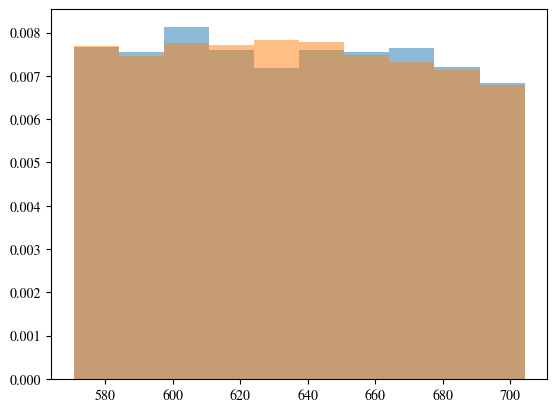

In [9]:
plt.hist(tabbgs['dist'],density=True,alpha=0.5)
plt.hist(bgsrantab['dist'],density=True,alpha=0.5)


## Make clustering measurements ##

In [10]:
import importlib
import tools
importlib.reload(tools)

<module 'tools' from '/global/u1/c/crmiller/bgsmaps/tools.py'>

In [11]:
#use less data so as to save time
tabbgs = tabbgs[::4]
bgsrantab = bgsrantab[::4]

In [12]:
#split into quantiles by luminosity
#test our RA-DEC slicing algorithm
#jackknife regions share RA/DEC boundaries (set by bgs_21_35) across all catalogs
quiltmasks_bgs, quiltmasks_ran = tools.quiltMasksFromReference(tabbgs, [tabbgs, bgsrantab], 7, 7)

D1tab = tabbgs
D2tab = tabbgs
D1masks_jack = quiltmasks_bgs
D2masks_jack = quiltmasks_bgs
stringname = "bgsclusteringxbgsclustering"

start = np.log10(0.05)#np.log10(0.05)
stop = np.log10(50)
edges = [np.logspace(start,stop,num=30),[-40,40]] #[np.logspace(start,stop,num=20),[-40,40]]

In [13]:
#convert from Mpc/h to Mpc (?)
D2counts = tools.getJackknifeCounts(D1tab, D2tab, D1masks_jack, D2masks_jack, stringname,edges=edges, useD1weights= True, useD2weights = True)

In [14]:
stringname = "BGSclusteringxran"
reftab = tabbgs
sampletab = bgsrantab
samplemasks_jack = quiltmasks_ran
refmasks_jack = quiltmasks_bgs
rancounts = tools.getJackknifeCounts(reftab, sampletab, refmasks_jack, samplemasks_jack, stringname,edges = edges,useD1weights = True, useD2weights = False)

## Plot BGS and Abacus together ##

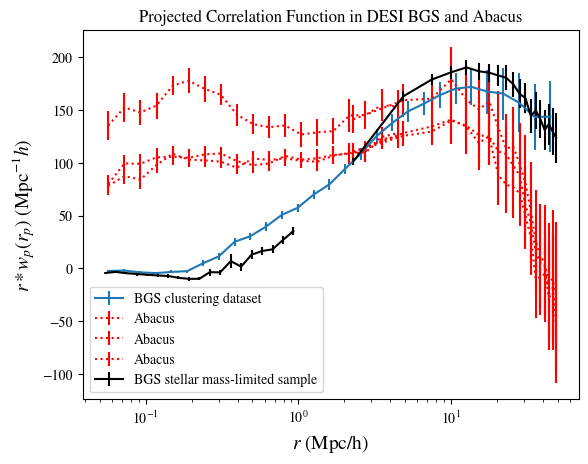

In [26]:
D1D2names= ["BGSxquantile_bgsclusteringxbgsclustering"]
D1R1name = "BGSxquantile_BGSclusteringxran"
rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,label = "BGS clustering dataset")


ranges = [[0,33],[33,66],[66,100]]    
names = ['Percentile 0-33','Percentile 33-66','Percentile 66-100']
for j in range(len(ranges)):
    D1D2names = []
    for i in np.arange(ranges[j][0],ranges[j][1]):
        D1D2names.append("BGSxquantile_rockstar_multsplit_quant"+str(i))
    D1R1name = "BGSxquantile_rockstarxran"
    rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
    plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,linestyle='dotted',label="Abacus",color='red')

for j in range(len(ranges)):
    D1D2names = []
    for i in np.arange(ranges[j][0],ranges[j][1]):
        D1D2names.append("BGSxquantile_rockstar_larger_quant"+str(i))
    D1R1name = "BGSxquantile_rockstarxran_larger"
    rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
    plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,linestyle='dotted',color='red')

D1D2names = ["BGSxquantile_bgsxbgs_IIPtest"]
D1R1name = "BGSxquantile_BGSxran_IIPtest"
rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,color='black')

D1D2names = ["BGSxquantile_bgsxbgs_IIPtest_smallr"]
D1R1name = "BGSxquantile_BGSxran_IIPtest_smallr"
rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,color='black',label = "BGS stellar mass-limited sample")
    
#plt.xscale('log')#, yerr = jackerror)
plt.ylabel(r"$r*w_p(r_p)$ (Mpc$^{-1}h$)")
plt.xlabel("$r$ (Mpc/h)")
plt.title("Projected Correlation Function in DESI BGS and Abacus")
plt.legend()
plt.xscale('log')

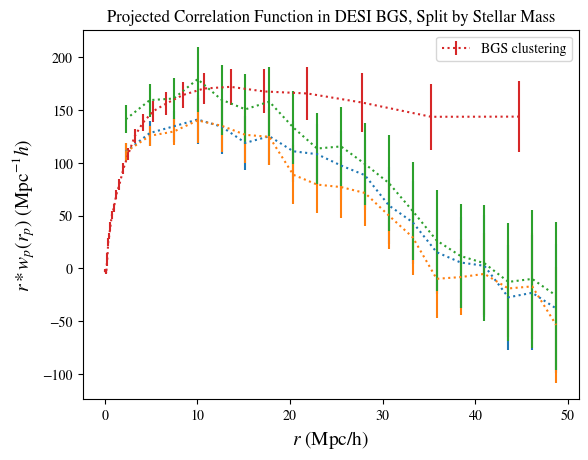

In [18]:
ranges = [[0,33],[33,66],[66,100]]
names = ['Percentile 0-33','Percentile 33-66','Percentile 66-100']

for j in range(len(ranges)):
    D1D2names = []
    for i in np.arange(ranges[j][0],ranges[j][1]):
        D1D2names.append("BGSxquantile_rockstar_larger_quant"+str(i))
    D1R1name = "BGSxquantile_rockstarxran_larger"
    rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
    plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,linestyle='dotted')

    
D1D2names= ["BGSxquantile_bgsclusteringxbgsclustering"]
D1R1name = "BGSxquantile_BGSclusteringxran"
rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
plt.errorbar(rcenters,DavisPeeblesEstimators,yerr = jackerror,linestyle='dotted',label = "BGS clustering")

#plt.xscale('log')#, yerr = jackerror)
plt.ylabel(r"$r*w_p(r_p)$ (Mpc$^{-1}h$)")
plt.xlabel("$r$ (Mpc/h)")
plt.title("Projected Correlation Function in DESI BGS, Split by Stellar Mass")
plt.legend()
#plt.xscale('log')

In [7]:
bw = tabbgs['BITWEIGHTS']
print(bw.dtype, bw.shape)                         # expect int64, (N, 2)
nbits = sum(np.unpackbits(np.ascontiguousarray(bw[:, k]).view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1) for k in range(bw.shape[1]))
iip = 129 / (1 + nbits)
print(np.percentile(iip, [0, 5, 50, 95, 100]), np.mean(iip))

int64 (481494, 2)
[ 1.          1.          1.04878049  2.6875     64.5       ] 1.3583252757747488
